Solutions of PDEs are operators that act as mappings between function spaces. They take initial conditions, boundary conditions, and source terms as inputs and yield the PDE solution as output. For instance, in fluid dynamics, the solution operator can compute the flow profile at a specific future time (e.g. $T = 1$) given the initial flow and boundary conditions.

\\


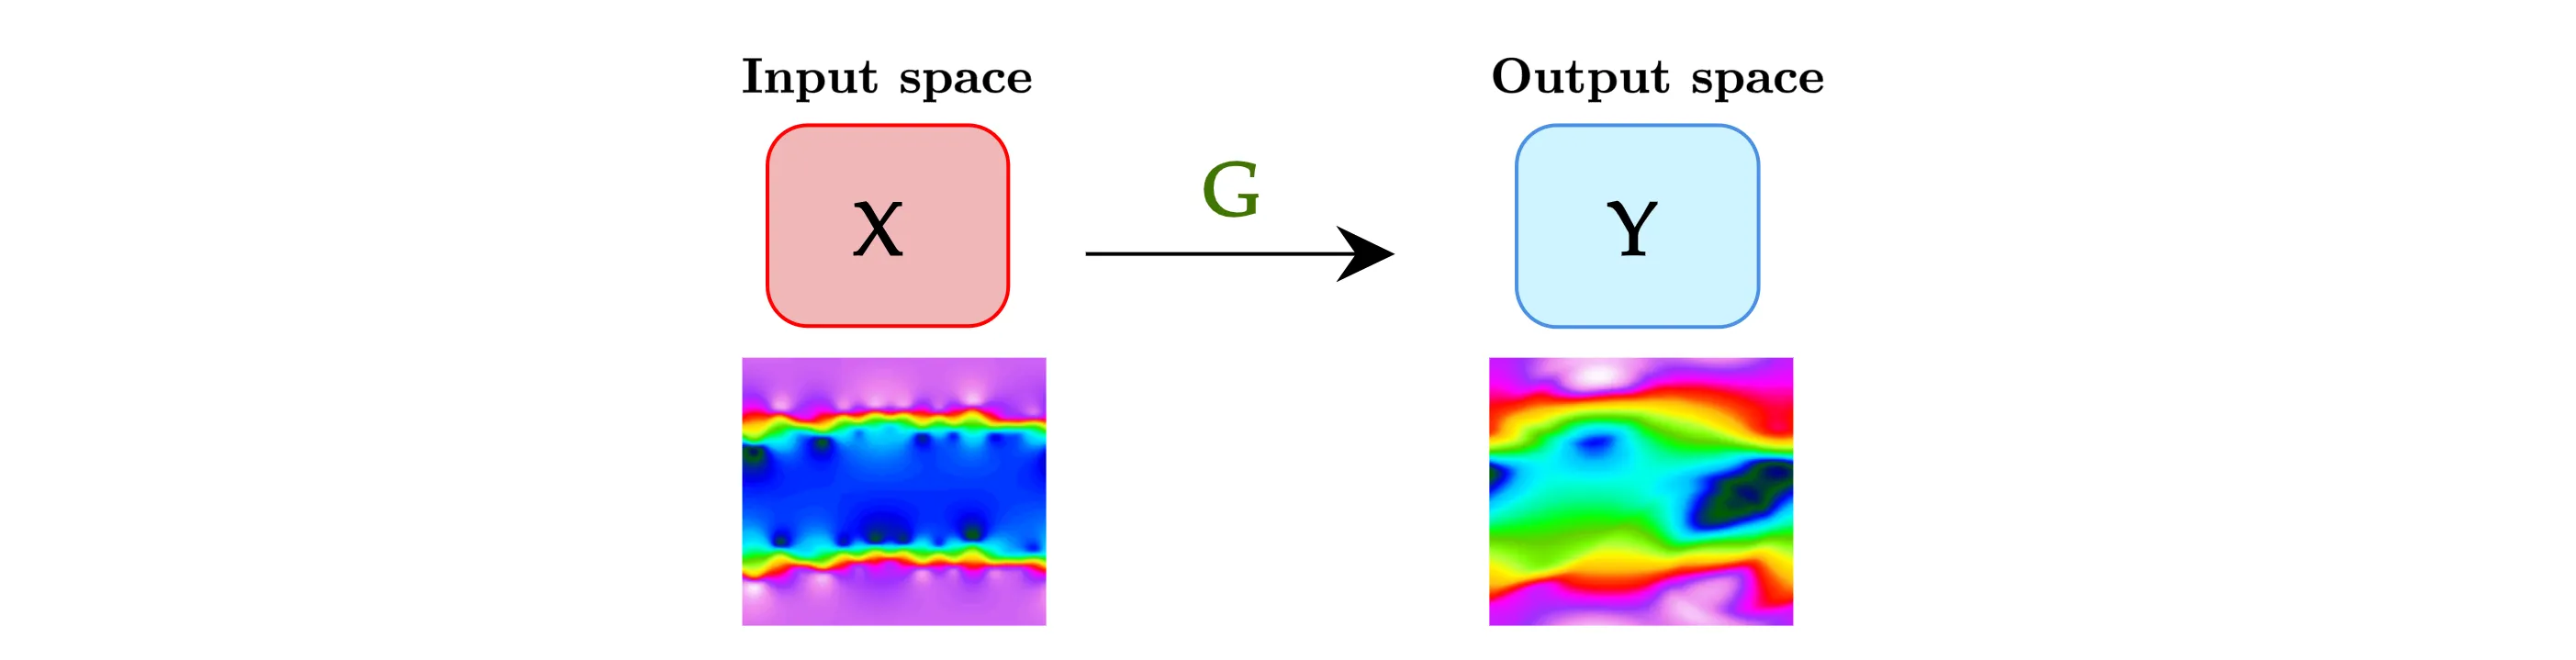

In **operator learning**, models are tasked with handling functions as inputs and outputs, which are stored on a computer in their **discrete representations** (e.g. images). They should have ability to process and generalize across various representations of the inputs, such as different mesh refinements.

Data-driven models that exhibit the mentioned properties are commonly known as ***Neural Operators***.

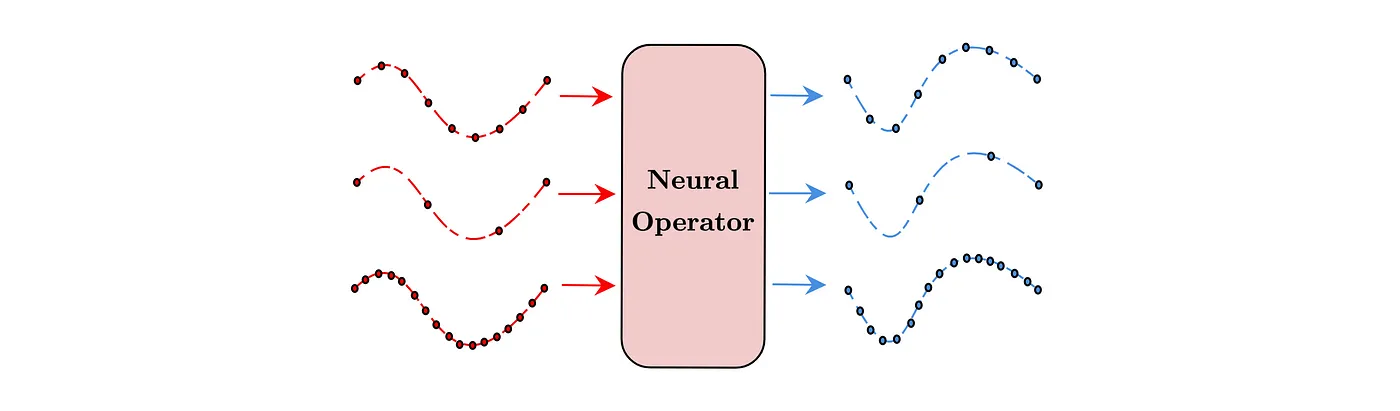



## Fourier Neural Operator (FNO)

- Introduced in the paper [Fourier Neural Operator for Parametric Partial Differential Equations](https://arxiv.org/abs/2010.08895).
- FNO is formulated as an **iterative architecture**
- FNO uses **convolutions** parametrized in the **frequency domain** (**global** operations)
- FNO uses **skip connections** to enchance the training

First layer is the **lifting layer** (in the channel dimension, increases the number of channels), while the last layer is the **projection layer** (reduces the number of channels.

\\

You can read the blog at [FNO blog](https://zongyi-li.github.io/blog/2020/fourier-pde/).


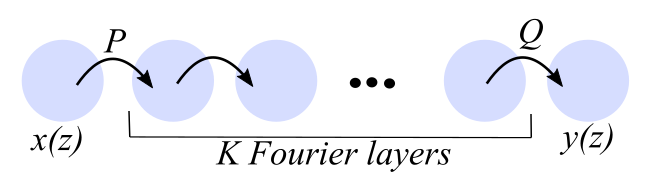

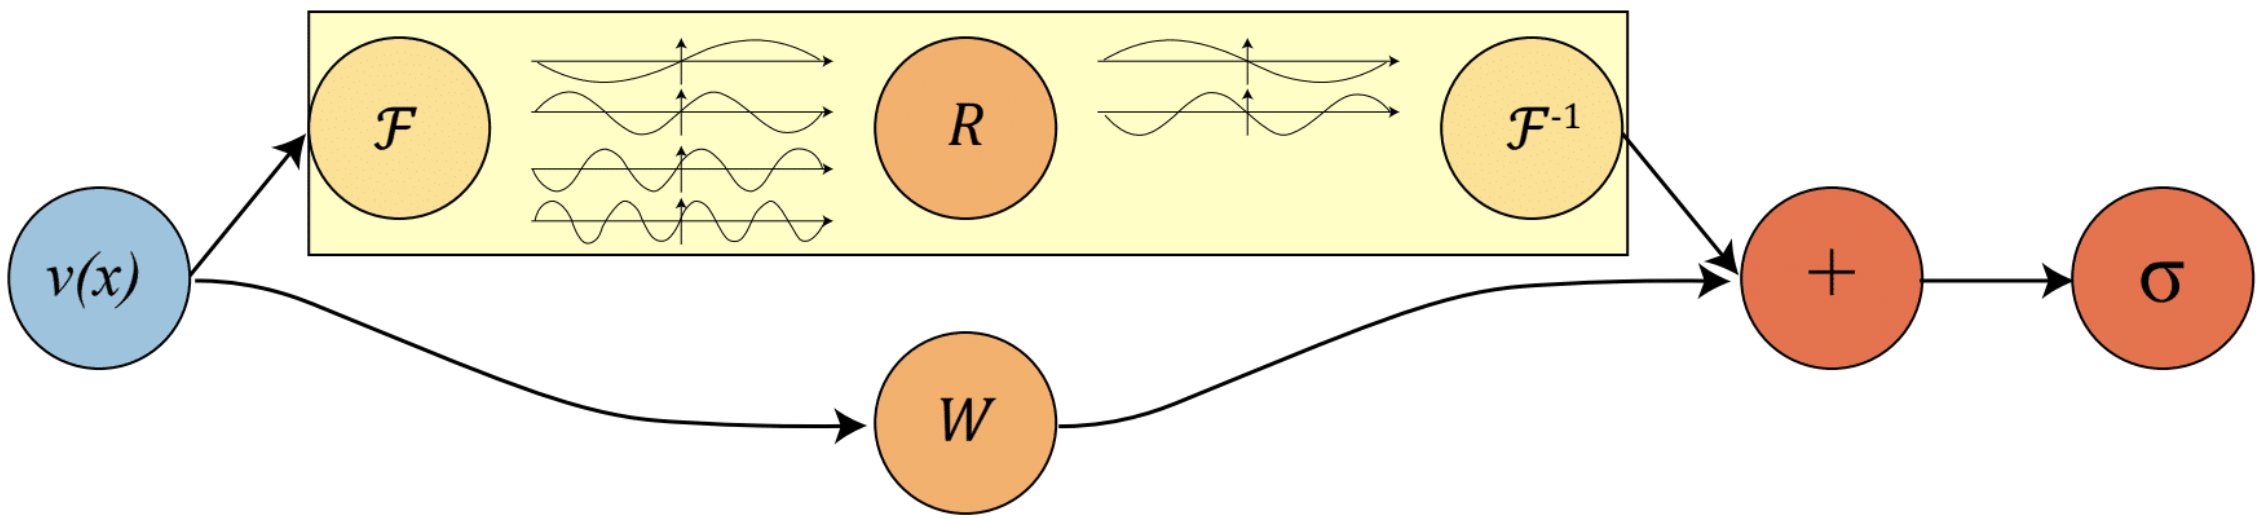

# Operator Learing - Fourier Neural Operator

The Fourier layer just consists of three steps:

1. Fourier transform (using FFT)

2. Linear transform on the lower Fourier modes

3. Inverse Fourier transform

In [340]:
import torch
import torch.nn as nn
import os
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F
from torch.optim import Adam
import matplotlib.pyplot as plt
import random

In [341]:
def activation(name):
    if name in ['tanh', 'Tanh']:
        return nn.Tanh()
    elif name in ['relu', 'ReLU']:
        return nn.ReLU(inplace=True)
    elif name in ['lrelu', 'LReLU']:
        return nn.LeakyReLU(inplace=True)
    elif name in ['sigmoid', 'Sigmoid']:
        return nn.Sigmoid()
    elif name in ['softplus', 'Softplus']:
        return nn.Softplus(beta=4)
    elif name in ['celu', 'CeLU']:
        return nn.CELU()
    elif name in ['elu']:
        return nn.ELU()
    elif name in ['mish']:
        return nn.Mish()
    else:
        raise ValueError('Unknown activation function')


\\

- We define Fourier layer in 1d (or spectral convolution)

In [342]:
# Spectral (or Fourier) layer in 1d

class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes1):
        super(SpectralConv1d, self).__init__()

        """
        1D Fourier layer. It does FFT, linear transform, and Inverse FFT.
        """

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes1 = modes1

        self.scale = (1 / (in_channels * out_channels))
        self.weights1 = nn.Parameter(self.scale * torch.rand(in_channels, out_channels, self.modes1, dtype=torch.cfloat))

    # Complex multiplication
    def compl_mul1d(self, input, weights):
        # (batch, in_channel, x ), (in_channel, out_channel, x) -> (batch, out_channel, x)
        return torch.einsum("bix,iox->box", input, weights)

    def forward(self, x):
        batchsize = x.shape[0]
        # x.shape == [batch_size, in_channels, number of grid points]
        # hint: use torch.fft library torch.fft.rfft
        # use DFT to approximate the fourier transform

        # Compute Fourier coefficients
        x_ft = torch.fft.rfft(x)

        # Multiply relevant Fourier modes
        out_ft = torch.zeros(batchsize, self.out_channels, x.size(-1) // 2 + 1, device=x.device, dtype=torch.cfloat)
        out_ft[:, :, :self.modes1] = self.compl_mul1d(x_ft[:, :, :self.modes1], self.weights1)

        # Return to physical space
        x = torch.fft.irfft(out_ft, n=x.size(-1))
        return x


\\

- The *FNO1d* uses *SpectralConv1d* as its crucial part.

In [343]:
class FNO1d(nn.Module):
    def __init__(self, modes, width):
        super(FNO1d, self).__init__()

        """
        The overall network. It contains 4 layers of the Fourier layer.
        1. Lift the input to the desire channel dimension by self.fc0 .
        2. 4 layers of the integral operators u' = (W + K)(u).
            W defined by self.w; K defined by self.conv .
        3. Project from the channel space to the output space by self.fc1 and self.fc2 .

        input: the solution of the initial condition and location (a(x), x)
        input shape: (batchsize, x=s, c=2)
        output: the solution of a later timestep
        output shape: (batchsize, x=s, c=1)
        """

        self.modes1 = modes
        self.width = width
        self.padding = 1  # pad the domain if input is non-periodic
        self.linear_p = nn.Linear(2, self.width)  # input channel is 2: (u0(x), x) --> GRID IS INCLUDED!

        self.spect1 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect2 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect3 = SpectralConv1d(self.width, self.width, self.modes1)
        self.lin0 = nn.Conv1d(self.width, self.width, 1)
        self.lin1 = nn.Conv1d(self.width, self.width, 1)
        self.lin2 = nn.Conv1d(self.width, self.width, 1)

        self.linear_q = nn.Linear(self.width, 32)
        self.output_layer = nn.Linear(32, 1)

        self.activation = torch.nn.Tanh()

    def fourier_layer(self, x, spectral_layer, conv_layer):
        return self.activation(spectral_layer(x) + conv_layer(x))

    def linear_layer(self, x, linear_transformation):
        return self.activation(linear_transformation(x))

    def forward(self, x):
        # grid = self.get_grid(x.shape, x.device)
        # x = torch.cat((x, grid), dim=-1)
        x = self.linear_p(x)
        x = x.permute(0, 2, 1)

        # x = F.pad(x, [0, self.padding])  # pad the domain if input is non-periodic

        x = self.fourier_layer(x, self.spect1, self.lin0)
        x = self.fourier_layer(x, self.spect2, self.lin1)
        x = self.fourier_layer(x, self.spect3, self.lin2)

        # x = x[..., :-self.padding]  # pad the domain if input is non-periodic
        x = x.permute(0, 2, 1)

        x = self.linear_layer(x, self.linear_q)
        x = self.output_layer(x)
        return x


## Example

We will solve Allen-Cahn equation:

## $u_t = \Delta u - ϵ^2 u (u^2 - 1),\quad u\in\mathbb{R}×\mathbb{R_{>0}}$

Operator that we wish to learn is

## $\mathcal{G}: u(\cdot, t = 0) \mapsto  u(\cdot, t = 1)$

Note that the data is generated for you (see the files *AC_data_input.npy* and *AC_data_output.npy*).

In [344]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

## Task 1: One-to-One Training

In [345]:
# Load the data
# - FNO_wave_equation/dataset/train_sol.npy

train_data = torch.from_numpy(np.load("../FNO_wave_equation/dataset/train_sol.npy")).type(torch.float32)
test_data = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol.npy")).type(torch.float32)

# only use the trajectories at t=0.0 as input
data_dim = train_data.shape[-1]
x_data = train_data[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
x_data[:, :, 1] = torch.linspace(0, 1, data_dim)
# use trajectories at t=1.0 as output
y_data = train_data[:, 4, :]

x_data_test = test_data[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
x_data_test[:, :, 1] = torch.linspace(0, 1, data_dim)
y_data_test = test_data[:, 4, :]


### Choose 64 trajectories for training and 64 trajectories for validation

In [346]:
n_train = 64 # number of training samples
# randomly choose n_train samples
train_idx = np.random.choice(train_data.shape[0], n_train, replace=False)
val_idx = np.array(list(set(range(train_data.shape[0])) - set(train_idx)))

input_function_train = x_data[train_idx, :]
output_function_train = y_data[train_idx, :]
input_function_val = x_data[val_idx, :]
output_function_val = y_data[val_idx, :]

batch_size = 10

training_set = DataLoader(TensorDataset(input_function_train, output_function_train), batch_size=batch_size, shuffle=True)
validation_set = DataLoader(TensorDataset(input_function_val, output_function_val), batch_size=batch_size, shuffle=False)
testing_set = DataLoader(TensorDataset(x_data_test, y_data_test), batch_size=batch_size, shuffle=False)

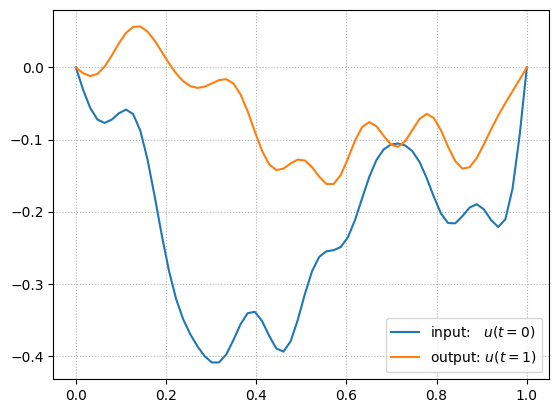

In [347]:
id_sample = 32

plt.plot(np.linspace(0,1,input_function_train.shape[1]),input_function_train[id_sample, :, 0], label = "input:   $u(t = 0)$")
plt.plot(np.linspace(0,1,input_function_train.shape[1]),output_function_train[id_sample,:], label = "output: $u(t = 1)$")
plt.grid(True, which="both", ls=":")
plt.legend()

In [348]:
learning_rate = 0.001
epochs = 500 # set as 250 epochs for training
step_size = 50
gamma = 0.5

In [349]:
modes = 16
width = 64
fno = FNO1d(modes, width) # model


### Training

In [350]:
optimizer = Adam(fno.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

# save loss and Relative L2 norm
train_losses = []
val_L2_norms = []
l = torch.nn.MSELoss()
freq_print = 1
for epoch in range(epochs):
    train_mse = 0.0
    for step, (input_batch, output_batch) in enumerate(training_set):
        optimizer.zero_grad()
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = l(output_pred_batch, output_batch)
        loss_f.backward()
        optimizer.step()
        train_mse += loss_f.item()
    train_mse /= len(training_set)
    train_losses.append(train_mse)

    scheduler.step()

    with torch.no_grad():
        fno.eval()
        val_relative_l2 = 0.0
        for step, (input_batch, output_batch) in enumerate(validation_set):
            output_pred_batch = fno(input_batch).squeeze(2)
            loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
            val_relative_l2 += loss_f.mean().item()
        val_relative_l2 /= len(validation_set)
        val_L2_norms.append(val_relative_l2)

    if epoch % freq_print == 0: print("######### Epoch:", epoch, " ######### Train Loss:", train_mse, " ######### Relative L2 Validation Norm:", val_relative_l2)



######### Epoch: 0  ######### Train Loss: 0.02740287860589368  ######### Relative L2 Validation Norm: 79.17267390659877
######### Epoch: 1  ######### Train Loss: 0.01730634338621582  ######### Relative L2 Validation Norm: 80.8316901070731
######### Epoch: 2  ######### Train Loss: 0.017290326367531503  ######### Relative L2 Validation Norm: 79.07097734723773
######### Epoch: 3  ######### Train Loss: 0.016475414857268333  ######### Relative L2 Validation Norm: 79.21475001743862
######### Epoch: 4  ######### Train Loss: 0.01682587792830808  ######### Relative L2 Validation Norm: 76.79825265066964
######### Epoch: 5  ######### Train Loss: 0.01644092266048704  ######### Relative L2 Validation Norm: 76.81581333705357
######### Epoch: 6  ######### Train Loss: 0.01696894783526659  ######### Relative L2 Validation Norm: 78.43973541259766
######### Epoch: 7  ######### Train Loss: 0.015827658187065805  ######### Relative L2 Validation Norm: 76.9682867867606
######### Epoch: 8  ######### Train Los

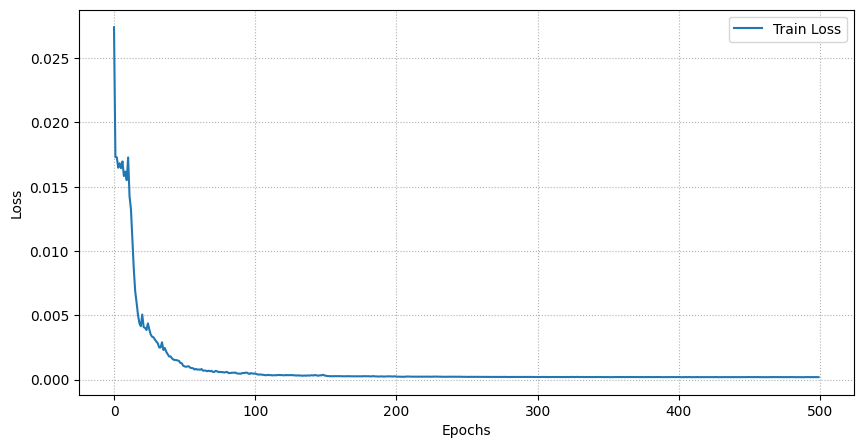

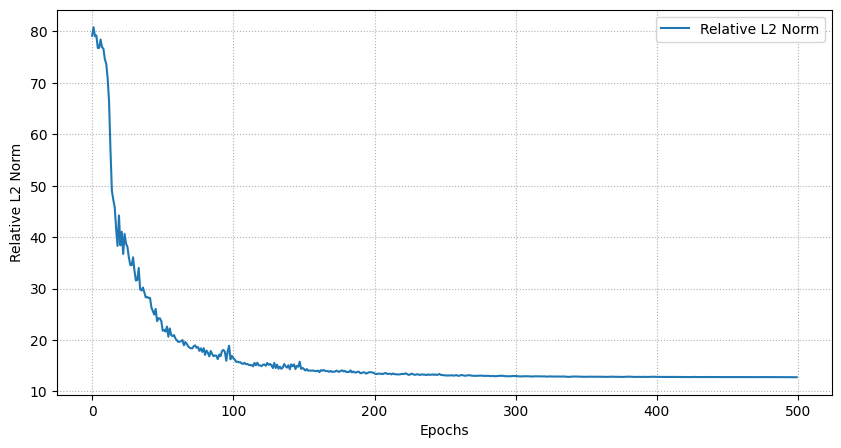

In [351]:
# plot the loss and relative L2 norm
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(val_L2_norms, label="Relative L2 Norm")
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Norm")
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()


### Plot

Relative L2 error:  11.597818374633789


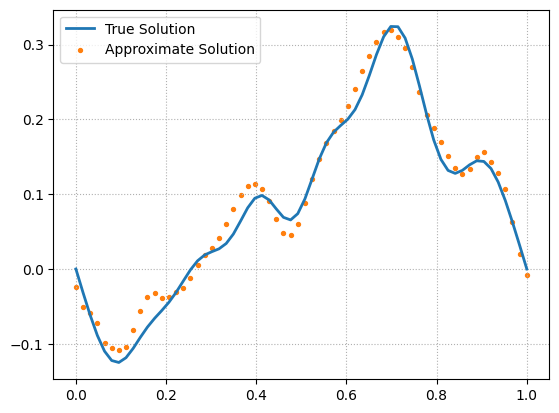

In [352]:
idx_data = 10
input_function_test_n = input_function_val[idx_data, :].unsqueeze(0)
output_function_test_n = output_function_val[idx_data, :].unsqueeze(0)
#print(input_function_test_n.shape)
#print(output_function_test_n.shape)

output_function_test_pred_n = fno(input_function_test_n)
#print(output_function_test_pred_n.shape)
#print(input_function_test_n[0,:,1])
plt.figure()
plt.grid(True, which="both", ls=":")
plt.plot(input_function_test_n[0,:,1].detach(), output_function_test_n[0].detach(), label="True Solution", c="C0", lw=2)
plt.scatter(input_function_test_n[0,:,1].detach(), output_function_test_pred_n[0].detach(), label="Approximate Solution", s=8, c="C1")
p = 2
err = (torch.mean(abs(output_function_test_n.detach().reshape(-1, ) - output_function_test_pred_n.detach().reshape(-1, )) ** p) / torch.mean(abs(output_function_test_n.detach()) ** p)) ** (1 / p) * 100
print("Relative L2 error: ", err.item())
plt.legend()

### Testing on test_sol.npy

In [353]:
with torch.no_grad():
    fno.eval()
    test_relative_l2 = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2 += loss_f.mean().item()
    test_relative_l2 /= len(testing_set)
    print("######### Relative L2 Test Norm:", test_relative_l2)

######### Relative L2 Test Norm: 13.916699482844425


## Task 2: Testing on Different Resolutions

In [354]:
# Load the data of different resolutions
test_data_res_32 = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol_res_32.npy")).type(torch.float32)
test_data_res_64 = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol_res_64.npy")).type(torch.float32)
test_data_res_96 = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol_res_96.npy")).type(torch.float32)
test_data_res_128 = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol_res_128.npy")).type(torch.float32)

# only use the trajectories at t=0.0 as input
x_data_test_res_32 = test_data_res_32[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
# create the grid
x_data_test_res_32[:, :, 1] = torch.linspace(0, 1, 32)
# use trajectories at t=1.0 as output
y_data_test_res_32 = test_data_res_32[:, 1, :]

x_data_test_res_64 = test_data_res_64[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
x_data_test_res_64[:, :, 1] = torch.linspace(0, 1, 64)
y_data_test_res_64 = test_data_res_64[:, 1, :]

x_data_test_res_96 = test_data_res_96[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
x_data_test_res_96[:, :, 1] = torch.linspace(0, 1, 96)
y_data_test_res_96 = test_data_res_96[:, 1, :]

x_data_test_res_128 = test_data_res_128[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
x_data_test_res_128[:, :, 1] = torch.linspace(0, 1, 128)
y_data_test_res_128 = test_data_res_128[:, 1, :]

testing_set_res_32 = DataLoader(TensorDataset(x_data_test_res_32, y_data_test_res_32), batch_size=batch_size, shuffle=False)
testing_set_res_64 = DataLoader(TensorDataset(x_data_test_res_64, y_data_test_res_64), batch_size=batch_size, shuffle=False)
testing_set_res_96 = DataLoader(TensorDataset(x_data_test_res_96, y_data_test_res_96), batch_size=batch_size, shuffle=False)
testing_set_res_128 = DataLoader(TensorDataset(x_data_test_res_128, y_data_test_res_128), batch_size=batch_size, shuffle=False)

# test the model on resolution 32
with torch.no_grad():
    fno.eval()
    test_relative_l2_res_32 = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set_res_32):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_res_32 += loss_f.mean().item()
    test_relative_l2_res_32 /= len(testing_set_res_32)
    print("######### Resolution: 32 ######## Relative L2 Test Norm:", test_relative_l2_res_32)

# test the model on resolution 64
with torch.no_grad():
    fno.eval()
    test_relative_l2_res_64 = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set_res_64):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_res_64 += loss_f.mean().item()
    test_relative_l2_res_64 /= len(testing_set_res_64)
    print("######### Resolution: 64 ######## Relative L2 Test Norm:", test_relative_l2_res_64)

# test the model on resolution 96
with torch.no_grad():
    fno.eval()
    test_relative_l2_res_96 = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set_res_96):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_res_96 += loss_f.mean().item()
    test_relative_l2_res_96 /= len(testing_set_res_96)
    print("######### Resolution: 96 ######## Relative L2 Test Norm:", test_relative_l2_res_96)

# test the model on resolution 128
with torch.no_grad():
    fno.eval()
    test_relative_l2_res_128 = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set_res_128):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_res_128 += loss_f.mean().item()
    test_relative_l2_res_128 /= len(testing_set_res_128)
    print("######### Resolution: 128 ######## Relative L2 Test Norm:", test_relative_l2_res_128)


######### Resolution: 32 ######## Relative L2 Test Norm: 14.45541895352877
######### Resolution: 64 ######## Relative L2 Test Norm: 13.894454809335562
######### Resolution: 96 ######## Relative L2 Test Norm: 13.804214184100811
######### Resolution: 128 ######## Relative L2 Test Norm: 13.860101553109976


Relative L2 error:  12.182700157165527


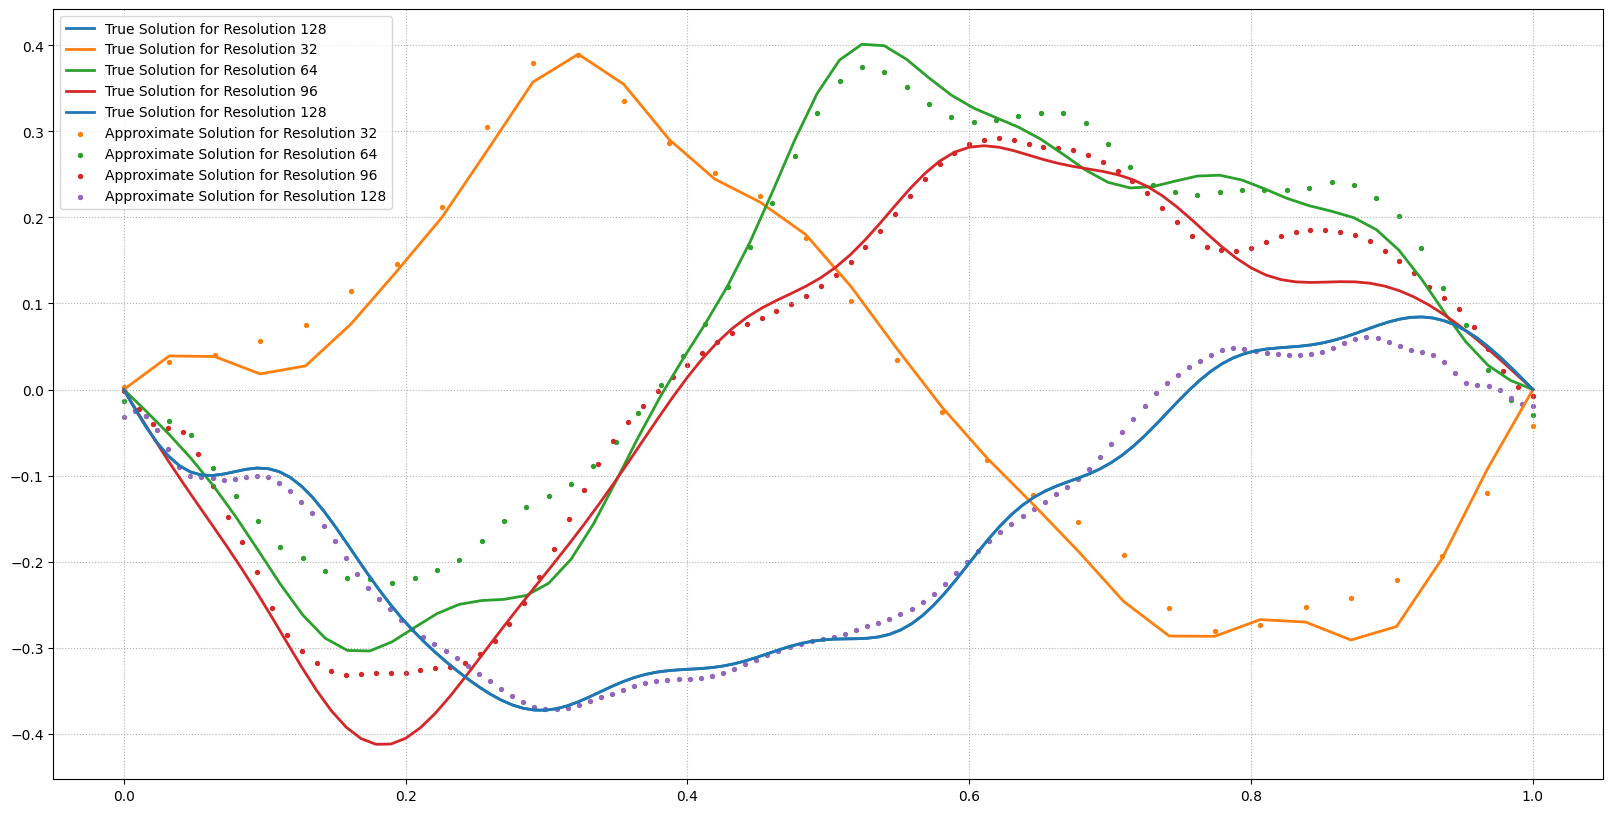

In [355]:
# random chose one trajectory to plot
idx_data = 20
input_function_test_n_res_32 = x_data_test_res_32[idx_data, :].unsqueeze(0)
output_function_test_n_res_32 = y_data_test_res_32[idx_data, :].unsqueeze(0)

input_function_test_n_res_64 = x_data_test_res_64[idx_data, :].unsqueeze(0)
output_function_test_n_res_64 = y_data_test_res_64[idx_data, :].unsqueeze(0)

input_function_test_n_res_96 = x_data_test_res_96[idx_data, :].unsqueeze(0)
output_function_test_n_res_96 = y_data_test_res_96[idx_data, :].unsqueeze(0)

input_function_test_n_res_128 = x_data_test_res_128[idx_data, :].unsqueeze(0)
output_function_test_n_res_128 = y_data_test_res_128[idx_data, :].unsqueeze(0)

output_function_test_pred_n_res_32 = fno(input_function_test_n_res_32)
output_function_test_pred_n_res_64 = fno(input_function_test_n_res_64)
output_function_test_pred_n_res_96 = fno(input_function_test_n_res_96)
output_function_test_pred_n_res_128 = fno(input_function_test_n_res_128)

plt.figure(figsize=(20, 10))
plt.grid(True, which="both", ls=":")
plt.plot(input_function_test_n_res_128[0,:,1].detach(), output_function_test_n_res_128[0].detach(), label="True Solution for Resolution 128", c="C0", lw=2)
plt.plot(input_function_test_n_res_32[0,:,1].detach(), output_function_test_n_res_32[0].detach(), label="True Solution for Resolution 32", c="C1", lw=2)
plt.plot(input_function_test_n_res_64[0,:,1].detach(), output_function_test_n_res_64[0].detach(), label="True Solution for Resolution 64", c="C2", lw=2)
plt.plot(input_function_test_n_res_96[0,:,1].detach(), output_function_test_n_res_96[0].detach(), label="True Solution for Resolution 96", c="C3", lw=2)
plt.plot(input_function_test_n_res_128[0,:,1].detach(), output_function_test_n_res_128[0].detach(), label="True Solution for Resolution 128", c="C0", lw=2)
plt.scatter(input_function_test_n_res_32[0,:,1].detach(), output_function_test_pred_n_res_32[0].detach(), label="Approximate Solution for Resolution 32", s=8, c="C1")
plt.scatter(input_function_test_n_res_64[0,:,1].detach(), output_function_test_pred_n_res_64[0].detach(), label="Approximate Solution for Resolution 64", s=8, c="C2")
plt.scatter(input_function_test_n_res_96[0,:,1].detach(), output_function_test_pred_n_res_96[0].detach(), label="Approximate Solution for Resolution 96", s=8, c="C3")
plt.scatter(input_function_test_n_res_128[0,:,1].detach(), output_function_test_pred_n_res_128[0].detach(), label="Approximate Solution for Resolution 128", s=8, c="C4")

plt.legend()

p = 2
err = (torch.mean(abs(output_function_test_n_res_32.detach().reshape(-1, ) - output_function_test_pred_n_res_32.detach().reshape(-1, )) ** p) / torch.mean(abs(output_function_test_n_res_32.detach()) ** p)) ** (1 / p) * 100
print("Relative L2 error: ", err.item())
plt.legend()

## Task 3: Testing on Out-of-Distribution (OOD) Dataset

In [356]:
# Load the data of OOD
test_data_OOD = torch.from_numpy(np.load("../FNO_wave_equation/dataset/test_sol_OOD.npy")).type(torch.float32)
data_dim_OOD = test_data_OOD.shape[-1]
# only use the trajectories at t=0.0 as input
x_data_test_OOD = test_data_OOD[:, 0, :].unsqueeze(-1).repeat(1, 1, 2)
# create the grid
x_data_test_OOD[:, :, 1] = torch.linspace(0, 1, data_dim_OOD)
# use trajectories at t=1.0 as output
y_data_test_OOD = test_data_OOD[:, 1, :]

testing_set_OOD = DataLoader(TensorDataset(x_data_test_OOD, y_data_test_OOD), batch_size=batch_size, shuffle=False)

# test the model on OOD data
with torch.no_grad():
    fno.eval()
    test_relative_l2_OOD = 0.0
    for step, (input_batch, output_batch) in enumerate(testing_set_OOD):
        output_pred_batch = fno(input_batch).squeeze(2)
        loss_f = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_OOD += loss_f.mean().item()
    test_relative_l2_OOD /= len(testing_set_OOD)
    print("######### OOD dataset ######## Relative L2 Test Norm:", test_relative_l2_OOD)


######### OOD dataset ######## Relative L2 Test Norm: 17.91920588566707


## Task 4: All2All Training

### Define Time-conditional BN

In [357]:
#---------------------
# Time-conditional BN:
#---------------------

class FILM(torch.nn.Module):
    def __init__(self,
                channels,
                use_bn = True):
        super(FILM, self).__init__()
        self.channels = channels

        self.inp2scale = nn.Linear(in_features=1, out_features=channels, bias=True)
        self.inp2bias = nn.Linear(in_features=1, out_features=channels, bias=True)

        self.inp2scale.weight.data.fill_(0)
        self.inp2scale.bias.data.fill_(1)
        self.inp2bias.weight.data.fill_(0)
        self.inp2bias.bias.data.fill_(0)

        if use_bn:
          self.norm = nn.BatchNorm1d(channels)
        else:
          self.norm = nn.Identity()

    def forward(self, x, time):

        # x = self.norm(x)
        time = time.reshape(-1,1).type_as(x)  # reshape time to (batch, 1)
        scale     = self.inp2scale(time)
        bias      = self.inp2bias(time)
        scale = scale.unsqueeze(1).expand_as(x) # (batch, 3) -> (batch, 1, 3) -> (batch, data_dim, 3)
        bias  = bias.unsqueeze(1).expand_as(x)

        return x * scale + bias


### Construct Time-dependent FNO Model

In [358]:
class FNO1d_time(nn.Module):
    def __init__(self, modes, width):
        super(FNO1d_time, self).__init__()

        """
        The overall network. It contains 4 layers of the Fourier layer.
        1. Lift the input to the desire channel dimension by self.fc0 .
        2. 4 layers of the integral operators u' = (W + K)(u).
            W defined by self.w; K defined by self.conv .
        3. Project from the channel space to the output space by self.fc1 and self.fc2 .

        input: the solution of the initial condition and location (a(x), x)
        input shape: (batchsize, x=s, c=2)
        output: the solution of a later timestep
        output shape: (batchsize, x=s, c=1)
        """

        self.modes1 = modes
        self.width = width
        self.padding = 1  # pad the domain if input is non-periodic
        self.linear_p = nn.Linear(3, self.width)  # input channel is 2: (u0(x), x) --> GRID IS INCLUDED!

        self.spect1 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect2 = SpectralConv1d(self.width, self.width, self.modes1)
        self.spect3 = SpectralConv1d(self.width, self.width, self.modes1)
        self.lin0 = nn.Conv1d(self.width, self.width, 1)
        self.lin1 = nn.Conv1d(self.width, self.width, 1)
        self.lin2 = nn.Conv1d(self.width, self.width, 1)

        self.linear_q = nn.Linear(self.width, 32)
        self.output_layer = nn.Linear(32, 1)

        self.activation = torch.nn.Tanh()
        self.film = FILM(channels = 3, use_bn = True)

    def fourier_layer(self, x, spectral_layer, conv_layer):
        return self.activation(spectral_layer(x) + conv_layer(x))

    def linear_layer(self, x, linear_transformation):
        return self.activation(linear_transformation(x))

    def forward(self, x, time):
        # grid = self.get_grid(x.shape, x.device)
        # x = torch.cat((x, grid), dim=-1)
        x = self.film(x, time)
        x = self.linear_p(x)
        x = x.permute(0, 2, 1)

        # x = F.pad(x, [0, self.padding])  # pad the domain if input is non-periodic

        x = self.fourier_layer(x, self.spect1, self.lin0)
        x = self.fourier_layer(x, self.spect2, self.lin1)
        x = self.fourier_layer(x, self.spect3, self.lin2)

        # x = x[..., :-self.padding]  # pad the domain if input is non-periodic
        x = x.permute(0, 2, 1)

        x = self.linear_layer(x, self.linear_q)
        x = self.output_layer(x)
        return x


In [359]:
# construct the dataset
from torch.utils.data import DataLoader, Dataset
class PDEDataset(Dataset):
    def __init__(self,
                 which="training", 
                 data = None,
                 training_samples = 256):

        self.data = data
        self.T = self.data.shape[1]
        print("Number of time steps: ", self.T)
        # Precompute all possible (t_initial, t_final) pairs within the specified range.
        self.time_pairs = [(i, j) for i in range(0, self.T) for j in range(i + 1, self.T)]
        print("Time pairs: ", self.time_pairs)
        self.len_times  = len(self.time_pairs)
        print("Number of time pairs: ", self.len_times)

        samples_num = self.data.shape[0]
        self.length = samples_num * self.len_times
        self.start = 0

        self.data_dim = self.data.shape[-1]
        self.grid = torch.linspace(0, 1, self.data_dim)

        self.mean = data.mean().item()
        self.std  = data.std().item()
        print("Mean: ", self.mean)
        print("Std: ", self.std)

        print("Dataset length: ", self.length)
        print("Dataset start: ", self.start)

    def __len__(self):
        return self.length

    def __getitem__(self, index):

        sample_idx = index // self.len_times
        # print("Sample idx: ", sample_idx)
        time_pair_idx = index % self.len_times
        t_inp, t_out = self.time_pairs[time_pair_idx]
        time = (t_out - t_inp) / (self.T - 1) # Normalize time

        inputs = self.data[sample_idx, t_inp].reshape(-1, 1)
        # inputs = (inputs - self.mean)/self.std #Normalize
        inputs_t = torch.ones(self.data_dim, 1).type(torch.float32) * t_inp / (self.T - 1)  # timestamp at t_inp
        inputs_grid = self.grid.reshape(-1, 1)
        inputs = torch.cat((inputs, inputs_grid, inputs_t), 1) #Cat time to the input

        outputs = self.data[sample_idx, t_out]
        # outputs = (outputs - self.mean)/self.std #Normalize

        return float(t_inp), float(t_out), float(time), inputs, outputs

In [360]:
train_data_all2all = train_data[train_idx]
val_data_all2all = train_data[val_idx]
test_data_all2all = test_data

training_set_all2all = DataLoader(PDEDataset("training", train_data_all2all), batch_size=batch_size, shuffle=True)
validation_set_all2all = DataLoader(PDEDataset("validation", val_data_all2all), batch_size=batch_size, shuffle=False)
testing_set_all2all = DataLoader(PDEDataset("test", test_data_all2all), batch_size=batch_size, shuffle=False)

learning_rate = 0.001
epochs = 500 # set as 500 epochs for training
step_size = 50
gamma = 0.5

modes = 16
width = 64
fno_all2all = FNO1d_time(modes, width) # model

Number of time steps:  5
Time pairs:  [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
Number of time pairs:  10
Mean:  -0.019095513969659805
Std:  0.31387701630592346
Dataset length:  640
Dataset start:  0
Number of time steps:  5
Time pairs:  [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
Number of time pairs:  10
Mean:  -0.00042046140879392624
Std:  0.3463423252105713
Dataset length:  640
Dataset start:  0
Number of time steps:  5
Time pairs:  [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
Number of time pairs:  10
Mean:  0.014024695381522179
Std:  0.32982710003852844
Dataset length:  1280
Dataset start:  0


In [361]:
optimizer_all2all = Adam(fno_all2all.parameters(), lr=learning_rate, weight_decay=1e-5)
scheduler_all2all = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma)

# save loss and Relative L2 norm
train_losses_all2all = []
val_L2_norms_all2all = []
l_all2all = torch.nn.MSELoss()
freq_print = 1
for epoch in range(epochs):
    train_mse_all2all = 0.0
    for step, (_, _, time_batch, input_batch, output_batch) in enumerate(training_set_all2all):
        optimizer_all2all.zero_grad()    
        time_batch = time_batch.type(torch.float32)
        output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
        loss_f_all2all = l(output_pred_batch, output_batch)
        loss_f_all2all.backward()
        optimizer_all2all.step()
        train_mse_all2all += loss_f_all2all.item()
    train_mse_all2all /= len(training_set_all2all)
    train_losses_all2all.append(train_mse_all2all)

    scheduler_all2all.step()

    with torch.no_grad():
        fno_all2all.eval()
        val_relative_l2_all2all = 0.0
        for step, (_, _, time_batch, input_batch, output_batch) in enumerate(validation_set_all2all):
            output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
            loss_f_all2all = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
            val_relative_l2_all2all += loss_f_all2all.sum().item()
        val_relative_l2_all2all /= 640
        val_L2_norms_all2all.append(val_relative_l2_all2all)

    if epoch % freq_print == 0: print("######### Epoch:", epoch, " ######### Train Loss:", train_mse_all2all, " ######### Relative L2 Validation Norm:", val_relative_l2_all2all)


/Users/moyangli/miniconda3/envs/pai-demos/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:131: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn("Detected call of `lr_scheduler.step()` before `optimizer.step()`. "


######### Epoch: 0  ######### Train Loss: 0.02982665716263  ######### Relative L2 Validation Norm: 74.63351173400879
######### Epoch: 1  ######### Train Loss: 0.023073863965692  ######### Relative L2 Validation Norm: 75.04208087921143
######### Epoch: 2  ######### Train Loss: 0.022672462670016102  ######### Relative L2 Validation Norm: 71.4046474456787
######### Epoch: 3  ######### Train Loss: 0.02172714495100081  ######### Relative L2 Validation Norm: 69.79939203262329
######### Epoch: 4  ######### Train Loss: 0.01885625447903294  ######### Relative L2 Validation Norm: 67.07328271865845
######### Epoch: 5  ######### Train Loss: 0.018147196838981472  ######### Relative L2 Validation Norm: 66.20928111076356
######### Epoch: 6  ######### Train Loss: 0.017227000964339823  ######### Relative L2 Validation Norm: 62.97705216407776
######### Epoch: 7  ######### Train Loss: 0.01735460241616238  ######### Relative L2 Validation Norm: 66.81795525550842
######### Epoch: 8  ######### Train Loss: 0

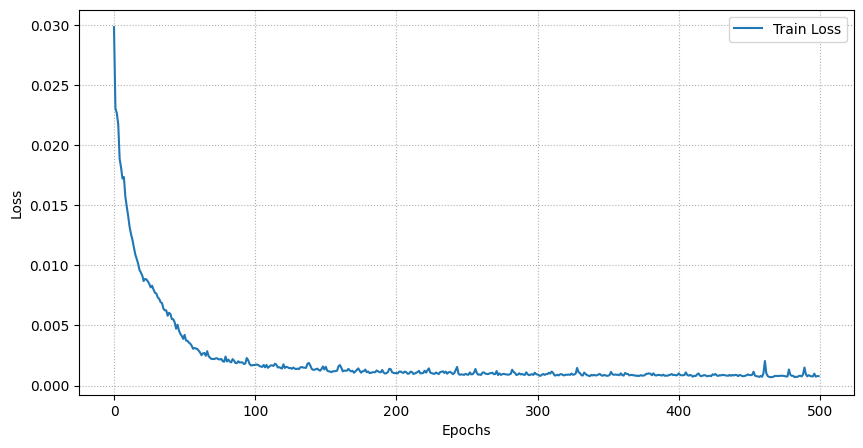

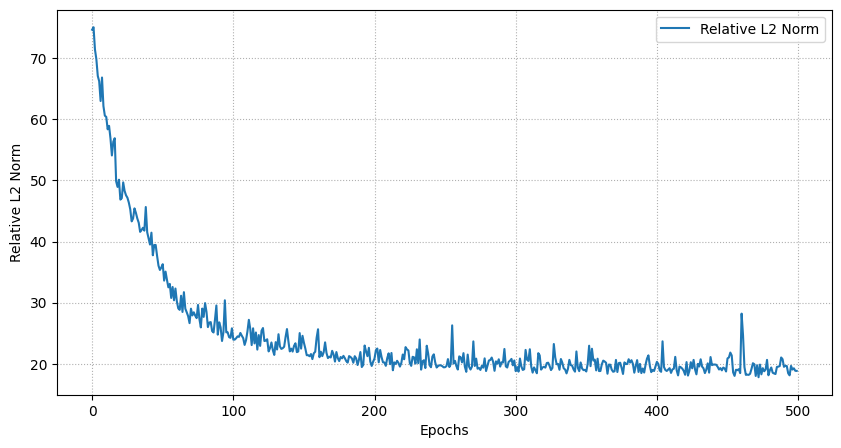

In [362]:
### convergence plot
plt.figure(figsize=(10, 5))
plt.plot(train_losses_all2all, label="Train Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(val_L2_norms_all2all, label="Relative L2 Norm")
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Norm")
plt.grid(True, which="both", ls=":")
plt.legend()
plt.show()


In [367]:
test_relative_l2_all2all = {
    "0.25": 0.0,
    "0.50": 0.0,
    "0.75": 0.0,
    "1.00": 0.0,
    "all": 0.0
}
len_val_all2all = {
    "0.25": 0.0,
    "0.50": 0.0,
    "0.75": 0.0,
    "1.00": 0.0
}
with torch.no_grad():
    fno_all2all.eval()
    for step, (_, t_out, time_batch, input_batch, output_batch) in enumerate(testing_set_all2all):
        output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
        loss_f_all2all = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        idx_0 = (t_out == 1).nonzero().squeeze(1)
        idx_1 = (t_out == 2).nonzero().squeeze(1)
        idx_2 = (t_out == 3).nonzero().squeeze(1)
        idx_3 = (t_out == 4).nonzero().squeeze(1)
        test_relative_l2_all2all["0.25"] += loss_f_all2all[idx_0].sum().item()
        test_relative_l2_all2all["0.50"] += loss_f_all2all[idx_1].sum().item()
        test_relative_l2_all2all["0.75"] += loss_f_all2all[idx_2].sum().item()
        test_relative_l2_all2all["1.00"] += loss_f_all2all[idx_3].sum().item()
        test_relative_l2_all2all["all"] += loss_f_all2all.mean().item()
        len_val_all2all["0.25"] += len(idx_0)
        len_val_all2all["0.50"] += len(idx_1)
        len_val_all2all["0.75"] += len(idx_2)
        len_val_all2all["1.00"] += len(idx_3)

    test_relative_l2_all2all["0.25"] /= len_val_all2all["0.25"]
    test_relative_l2_all2all["0.50"] /= len_val_all2all["0.50"]
    test_relative_l2_all2all["0.75"] /= len_val_all2all["0.75"]
    test_relative_l2_all2all["1.00"] /= len_val_all2all["1.00"]
    test_relative_l2_all2all["all"] /= len(testing_set_all2all)

    print("######### Relative L2 Test Norm at t=0.25:", test_relative_l2_all2all["0.25"])
    print("######### Relative L2 Test Norm at t=0.50:", test_relative_l2_all2all["0.50"])
    print("######### Relative L2 Test Norm at t=0.75:", test_relative_l2_all2all["0.75"])
    print("######### Relative L2 Test Norm at t=1.00:", test_relative_l2_all2all["1.00"])
    print("######### Relative L2 Test Norm for all timesteps:", test_relative_l2_all2all["all"])

######### Relative L2 Test Norm at t=0.25: 8.199059506878257
######### Relative L2 Test Norm at t=0.50: 15.771041626110673
######### Relative L2 Test Norm at t=0.75: 15.162341490387917
######### Relative L2 Test Norm at t=1.00: 25.56073148548603
######### Relative L2 Test Norm for all timesteps: 18.747109435498714


In [375]:
test_relative_l2_all2all = {
    "0.0-0.25": 0.0,
    "0.0-0.50": 0.0,
    "0.0-0.75": 0.0,
    "0.0-1.00": 0.0,
    "0.25-0.50": 0.0,
    "0.25-0.75": 0.0,
    "0.25-1.00": 0.0,
    "0.50-0.75": 0.0,
    "0.50-1.00": 0.0,
    "0.75-1.00": 0.0,
    "all": 0.0

}
len_val_all2all = {
    "0.0-0.25": 0.0,
    "0.0-0.50": 0.0,
    "0.0-0.75": 0.0,
    "0.0-1.00": 0.0,
    "0.25-0.50": 0.0,
    "0.25-0.75": 0.0,
    "0.25-1.00": 0.0,
    "0.50-0.75": 0.0,
    "0.50-1.00": 0.0,
    "0.75-1.00": 0.0,
}
with torch.no_grad():
    fno_all2all.eval()
    for step, (t_inp, t_out, time_batch, input_batch, output_batch) in enumerate(testing_set_all2all):
        output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
        loss_f_all2all = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        idx_0_1 = ((t_inp == 0) & (t_out == 1)).nonzero().squeeze(1)
        idx_0_2 = ((t_inp == 0) & (t_out == 2)).nonzero().squeeze(1)
        idx_0_3 = ((t_inp == 0) & (t_out == 3)).nonzero().squeeze(1)
        idx_0_4 = ((t_inp == 0) & (t_out == 4)).nonzero().squeeze(1)
        idx_1_2 = ((t_inp == 1) & (t_out == 2)).nonzero().squeeze(1)
        idx_1_3 = ((t_inp == 1) & (t_out == 3)).nonzero().squeeze(1)
        idx_1_4 = ((t_inp == 1) & (t_out == 4)).nonzero().squeeze(1)
        idx_2_3 = ((t_inp == 2) & (t_out == 3)).nonzero().squeeze(1)
        idx_2_4 = ((t_inp == 2) & (t_out == 4)).nonzero().squeeze(1)
        idx_3_4 = ((t_inp == 3) & (t_out == 4)).nonzero().squeeze(1)
        # print(time_batch)
        # print(input_batch[:, 0, 2])
        test_relative_l2_all2all["0.0-0.25"] += loss_f_all2all[idx_0_1].sum().item()
        test_relative_l2_all2all["0.0-0.50"] += loss_f_all2all[idx_0_2].sum().item()
        test_relative_l2_all2all["0.0-0.75"] += loss_f_all2all[idx_0_3].sum().item()
        test_relative_l2_all2all["0.0-1.00"] += loss_f_all2all[idx_0_4].sum().item()
        test_relative_l2_all2all["0.25-0.50"] += loss_f_all2all[idx_1_2].sum().item()
        test_relative_l2_all2all["0.25-0.75"] += loss_f_all2all[idx_1_3].sum().item()
        test_relative_l2_all2all["0.25-1.00"] += loss_f_all2all[idx_1_4].sum().item()
        test_relative_l2_all2all["0.50-0.75"] += loss_f_all2all[idx_2_3].sum().item()
        test_relative_l2_all2all["0.50-1.00"] += loss_f_all2all[idx_2_4].sum().item()
        test_relative_l2_all2all["0.75-1.00"] += loss_f_all2all[idx_3_4].sum().item()
        test_relative_l2_all2all["all"] += loss_f_all2all.mean().item()
        len_val_all2all["0.0-0.25"] += len(idx_0_1)
        len_val_all2all["0.0-0.50"] += len(idx_0_2)
        len_val_all2all["0.0-0.75"] += len(idx_0_3)
        len_val_all2all["0.0-1.00"] += len(idx_0_4)
        len_val_all2all["0.25-0.50"] += len(idx_1_2)
        len_val_all2all["0.25-0.75"] += len(idx_1_3)
        len_val_all2all["0.25-1.00"] += len(idx_1_4)
        len_val_all2all["0.50-0.75"] += len(idx_2_3)
        len_val_all2all["0.50-1.00"] += len(idx_2_4)
        len_val_all2all["0.75-1.00"] += len(idx_3_4)

    test_relative_l2_all2all["0.0-0.25"] /= len_val_all2all["0.0-0.25"]
    test_relative_l2_all2all["0.0-0.50"] /= len_val_all2all["0.0-0.50"]
    test_relative_l2_all2all["0.0-0.75"] /= len_val_all2all["0.0-0.75"]
    test_relative_l2_all2all["0.0-1.00"] /= len_val_all2all["0.0-1.00"]
    test_relative_l2_all2all["0.25-0.50"] /= len_val_all2all["0.25-0.50"]
    test_relative_l2_all2all["0.25-0.75"] /= len_val_all2all["0.25-0.75"]
    test_relative_l2_all2all["0.25-1.00"] /= len_val_all2all["0.25-1.00"]
    test_relative_l2_all2all["0.50-0.75"] /= len_val_all2all["0.50-0.75"]
    test_relative_l2_all2all["0.50-1.00"] /= len_val_all2all["0.50-1.00"]
    test_relative_l2_all2all["0.75-1.00"] /= len_val_all2all["0.75-1.00"]
    test_relative_l2_all2all["all"] /= len(testing_set_all2all)


    print("######### Relative L2 Test Norm at t=0.0-0.25:", test_relative_l2_all2all["0.0-0.25"])
    print("######### Relative L2 Test Norm at t=0.0-0.50:", test_relative_l2_all2all["0.0-0.50"])
    print("######### Relative L2 Test Norm at t=0.0-0.75:", test_relative_l2_all2all["0.0-0.75"])
    print("######### Relative L2 Test Norm at t=0.0-1.00:", test_relative_l2_all2all["0.0-1.00"])
    print("######### Relative L2 Test Norm at t=0.25-0.50:", test_relative_l2_all2all["0.25-0.50"])
    print("######### Relative L2 Test Norm at t=0.25-0.75:", test_relative_l2_all2all["0.25-0.75"])
    print("######### Relative L2 Test Norm at t=0.25-1.00:", test_relative_l2_all2all["0.25-1.00"])
    print("######### Relative L2 Test Norm at t=0.50-0.75:", test_relative_l2_all2all["0.50-0.75"])
    print("######### Relative L2 Test Norm at t=0.50-1.00:", test_relative_l2_all2all["0.50-1.00"])
    print("######### Relative L2 Test Norm at t=0.75-1.00:", test_relative_l2_all2all["0.75-1.00"])
    print("######### Relative L2 Test Norm for all timesteps:", test_relative_l2_all2all["all"])

######### Relative L2 Test Norm at t=0.0-0.25: 8.199059506878257
######### Relative L2 Test Norm at t=0.0-0.50: 11.448781153187156
######### Relative L2 Test Norm at t=0.0-0.75: 13.368114329874516
######### Relative L2 Test Norm at t=0.0-1.00: 20.476306810975075
######### Relative L2 Test Norm at t=0.25-0.50: 20.093302369117737
######### Relative L2 Test Norm at t=0.25-0.75: 13.00268604233861
######### Relative L2 Test Norm at t=0.25-1.00: 28.748891346156597
######### Relative L2 Test Norm at t=0.50-0.75: 19.116224203258753
######### Relative L2 Test Norm at t=0.50-1.00: 23.687523685395718
######### Relative L2 Test Norm at t=0.75-1.00: 29.330204121768475
######### Relative L2 Test Norm for all timesteps: 18.747109435498714


torch.Size([4, 64, 1])
torch.Size([4, 64, 1])
torch.Size([4, 64, 1])
torch.Size([1, 64, 1])


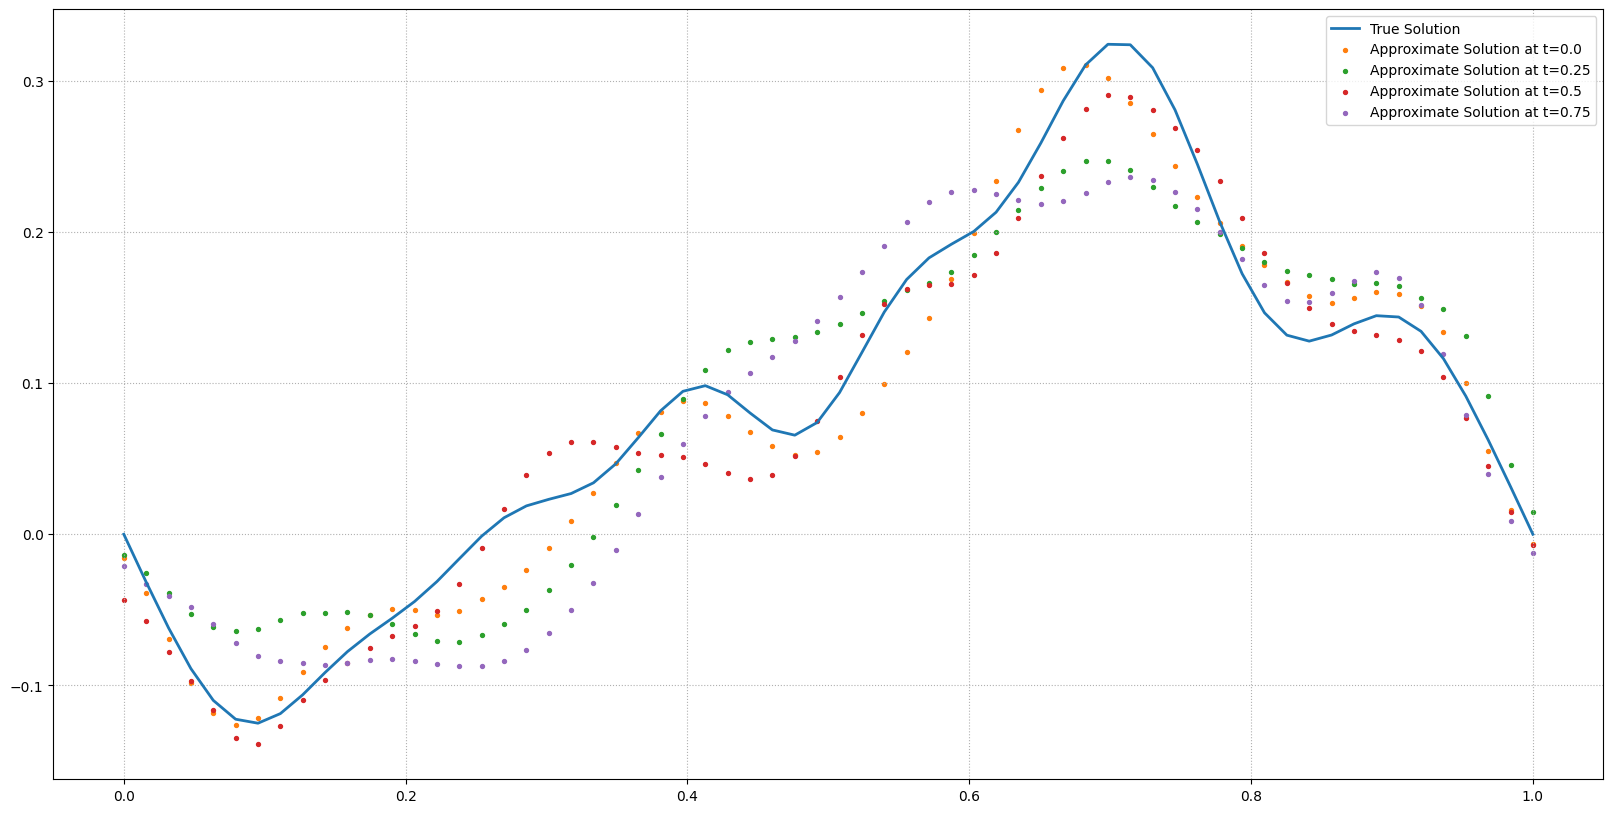

In [365]:
## vis one trajectory
idx_data = 10
input_data = val_data_all2all[idx_data, [0, 1, 2, 3]].reshape(4, -1, 1)
grid = torch.linspace(0, 1, input_data.shape[1]).reshape(1, -1, 1).repeat(input_data.shape[0], 1, 1)
time_data = torch.ones_like(grid) * 0.0
time_data[0, :, 0] = 0.0
time_data[1, :, 0] = 0.25
time_data[2, :, 0] = 0.5
time_data[3, :, 0] = 0.75

print(input_data.shape)
print(grid.shape)
print(time_data.shape)

input_batch = torch.cat((input_data, grid, time_data), 2)
time_batch = torch.tensor([1.0, 0.75, 0.5, 0.25]).reshape(1, -1, 1)
output_data = val_data_all2all[idx_data, 4].reshape(1, -1, 1)
print(output_data.shape)
output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
output_pred_batch = output_pred_batch.detach().numpy()

plt.figure(figsize=(20, 10))
plt.grid(True, which="both", ls=":")
plt.plot(grid[0], output_data[0], label="True Solution", c="C0", lw=2)
plt.scatter(grid[0], output_pred_batch[0], label="Approximate Solution at t=0.0", s=8, c="C1")
plt.scatter(grid[0], output_pred_batch[1], label="Approximate Solution at t=0.25", s=8, c="C2")
plt.scatter(grid[0], output_pred_batch[2], label="Approximate Solution at t=0.5", s=8, c="C3")
plt.scatter(grid[0], output_pred_batch[3], label="Approximate Solution at t=0.75", s=8, c="C4")

plt.legend()



### All2All Model testing on OOD dataset.

In [369]:
test_data_OOD_all2all = test_data_OOD

testing_set_OOD_all2all = DataLoader(PDEDataset("test", test_data_OOD_all2all), batch_size=batch_size, shuffle=False)

test_relative_l2_OOD_all2all = 0.0
len_val_OOD_all2all = 0.0
with torch.no_grad():
    fno_all2all.eval()
    for step, (_, _, time_batch, input_batch, output_batch) in enumerate(testing_set_OOD_all2all):
        output_pred_batch = fno_all2all(input_batch, time_batch).squeeze(2)
        loss_f_all2all = (torch.mean((output_pred_batch - output_batch) ** 2, dim=-1) / torch.mean(output_batch ** 2, dim=-1)) ** 0.5 * 100
        test_relative_l2_OOD_all2all += loss_f_all2all.sum().item()
        len_val_OOD_all2all += len(loss_f_all2all)

    test_relative_l2_OOD_all2all /= len_val_OOD_all2all
    print("######### Relative L2 Test Norm on OOD dataset:", test_relative_l2_OOD_all2all)

Number of time steps:  2
Time pairs:  [(0, 1)]
Number of time pairs:  1
Mean:  0.02524336241185665
Std:  0.34311428666114807
Dataset length:  128
Dataset start:  0
######### Relative L2 Test Norm on OOD dataset: 25.211400032043457
